- Nama: Muhammad Putra Harifin Pane
- Email: putraharifin@gmail.com
- id Dicoding: putraharifin25

**Employee Data**

** The data contains demographic details, work-related metrics and attrition flag.**

- EmployeeId - Employee Identifier
- Attrition - Did the employee attrition? (0=no, 1=yes)
- Age - Age of the employee
- BusinessTravel - Travel commitments for the job
- DailyRate - Daily salary
- Department - Employee Department
- DistanceFromHome - Distance from work to home (in km)
- Education - 1-Below College, 2-College, 3-Bachelor, 4-Master,5-Doctor
- EducationField - Field of Education
- EnvironmentSatisfaction - 1-Low, 2-Medium, 3-High, 4-Very High
- Gender - Employee's gender
- HourlyRate - Hourly salary
- JobInvolvement - 1-Low, 2-Medium, 3-High, 4-Very High
- JobLevel - Level of job (1 to 5)
- JobRole - Job Roles
- JobSatisfaction - 1-Low, 2-Medium, 3-High, 4-Very High
- MaritalStatus - Marital Status
- MonthlyIncome - Monthly salary
- MonthlyRate - Mounthly rate
- NumCompaniesWorked - Number of companies worked at
- Over18 - Over 18 years of age?
- OverTime - Overtime?
- PercentSalaryHike - The percentage increase in salary last year
- PerformanceRating - 1-Low, 2-Good, 3-Excellent, 4-Outstanding
- RelationshipSatisfaction - 1-Low, 2-Medium, 3-High, 4-Very High
- StandardHours - Standard Hours
- StockOptionLevel - Stock Option Level
- TotalWorkingYears - Total years worked
- TrainingTimesLastYear - Number of training attended last year
- WorkLifeBalance - 1-Low, 2-Good, 3-Excellent, 4-Outstanding
- YearsAtCompany - Years at Company
- YearsInCurrentRole - Years in the current role
- YearsSinceLastPromotion - Years since the last promotion
- YearsWithCurrManager - Years with the current manager



## Persiapan

Menyiapkan library yang dibutuhkan

In [ ]:
# Import library untuk analisis data dan visualisasi
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Pengaturan tampilan
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Library berhasil diimpor.")


Library berhasil diimpor.


In [ ]:
# Memuat dataset
df = pd.read_csv("/content/employee_data.csv")

# Menampilkan lima baris pertama
display(df.head())

# Memeriksa ukuran dataset
print("Jumlah baris dan kolom:", df.shape)


,EmployeeId,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,1,38,NaN,Travel_Frequently,1444,Human Resources,1,4,Other,1,4,Male,88,3,1,Human Resources,2,Married,2991,5224,0,Y,Yes,11,3,2,80,1,7,2,3,6,2,1,2
1,2,37,1.0,Travel_Rarely,1141,Research & Development,11,2,Medical,1,1,Female,61,1,2,Healthcare Representative,2,Married,4777,14382,5,Y,No,15,3,1,80,0,15,2,1,1,0,0,0
2,3,51,1.0,Travel_Rarely,1323,Research & Development,4,4,Life Sciences,1,1,Male,34,3,1,Research Scientist,3,Married,2461,10332,9,Y,Yes,12,3,3,80,3,18,2,4,10,0,2,7
3,4,42,0.0,Travel_Frequently,555,Sales,26,3,Marketing,1,3,Female,77,3,4,Sales Executive,2,Married,13525,14864,5,Y,No,14,3,4,80,1,23,2,4,20,4,4,8
4,5,40,NaN,Travel_Rarely,1194,Research & Development,2,4,Medical,1,3,Female,98,3,1,Research Scientist,3,Married,2001,12549,2,Y,No,14,3,2,80,3,20,2,3,5,3,0,2


Jumlah baris dan kolom: (1470, 35)


Menyiapkan data yang akan digunakan

## Data Understanding

In [ ]:
df.shape

(1470, 35)

In [ ]:
# Informasi umum dataset
df.info()

# Statistik deskriptif numerik
display(df.describe().T)

# Statistik deskriptif seluruh kolom
display(df.describe(include="all").T)

# Memeriksa missing values
missing_values = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Persentase (%)": (df.isnull().mean() * 100).round(2)
})

display(
    missing_values[missing_values["Missing Values"] > 0]
    .sort_values("Missing Values", ascending=False)
)

# Memeriksa data duplikat
print("Jumlah baris duplikat:", df.duplicated().sum())

# Memeriksa jumlah EmployeeId unik
print("Jumlah EmployeeId unik:", df["EmployeeId"].nunique())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   EmployeeId                1470 non-null   int64  
 1   Age                       1470 non-null   int64  
 2   Attrition                 1058 non-null   float64
 3   BusinessTravel            1470 non-null   object 
 4   DailyRate                 1470 non-null   int64  
 5   Department                1470 non-null   object 
 6   DistanceFromHome          1470 non-null   int64  
 7   Education                 1470 non-null   int64  
 8   EducationField            1470 non-null   object 
 9   EmployeeCount             1470 non-null   int64  
 10  EnvironmentSatisfaction   1470 non-null   int64  
 11  Gender                    1470 non-null   object 
 12  HourlyRate                1470 non-null   int64  
 13  JobInvolvement            1470 non-null   int64  
 14  JobLevel

,count,mean,std,min,25%,50%,75%,max
EmployeeId,1470.0,735.500000,424.496761,1.0,368.25,735.5,1102.75,1470.0
Age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
Attrition,1058.0,0.169187,0.375094,0.0,0.00,0.0,0.00,1.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.00,3.0,3.00,4.0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
EmployeeId,1470.0,NaN,NaN,NaN,735.5,424.496761,1.0,368.25,735.5,1102.75,1470.0
Age,1470.0,NaN,NaN,NaN,36.92381,9.135373,18.0,30.0,36.0,43.0,60.0
Attrition,1058.0,NaN,NaN,NaN,0.169187,0.375094,0.0,0.0,0.0,0.0,1.0
BusinessTravel,1470,3,Travel_Rarely,1043,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DailyRate,1470.0,NaN,NaN,NaN,802.485714,403.5091,102.0,465.0,802.0,1157.0,1499.0
Department,1470,3,Research & Development,961,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DistanceFromHome,1470.0,NaN,NaN,NaN,9.192517,8.106864,1.0,2.0,7.0,14.0,29.0
Education,1470.0,NaN,NaN,NaN,2.912925,1.024165,1.0,2.0,3.0,4.0,5.0
EducationField,1470,6,Life Sciences,606,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EmployeeCount,1470.0,NaN,NaN,NaN,1.0,0.0,1.0,1.0,1.0,1.0,1.0


,Missing Values,Persentase (%)
Attrition,412,28.03


Jumlah baris duplikat: 0
Jumlah EmployeeId unik: 1470


In [ ]:
# Memeriksa distribusi label Attrition
print("Distribusi Attrition:")
display(df["Attrition"].value_counts(dropna=False).sort_index())

# Memeriksa jumlah label yang valid
valid_attrition = df["Attrition"].notna().sum()
missing_attrition = df["Attrition"].isna().sum()

print("Jumlah label valid:", valid_attrition)
print("Jumlah label kosong:", missing_attrition)

# Membuat dataset dengan label Attrition yang valid
df_labeled = df.dropna(subset=["Attrition"]).copy()

# Memastikan label hanya bernilai 0 atau 1
print("Label unik:", sorted(df_labeled["Attrition"].unique()))

# Menghitung jumlah karyawan keluar dan tidak keluar
attrition_counts = df_labeled["Attrition"].value_counts().sort_index()

print("Tidak keluar (0):", attrition_counts.get(0, 0))
print("Keluar (1):", attrition_counts.get(1, 0))

# Menghitung attrition rate berdasarkan label yang tersedia
attrition_rate = (df_labeled["Attrition"] == 1).mean() * 100

print(f"Attrition rate pada data berlabel: {attrition_rate:.2f}%")

Distribusi Attrition:


,count
Attrition,
0.0,879
1.0,179
NaN,412


Jumlah label valid: 1058
Jumlah label kosong: 412
Label unik: [np.float64(0.0), np.float64(1.0)]
Tidak keluar (0): 879
Keluar (1): 179
Attrition rate pada data berlabel: 16.92%


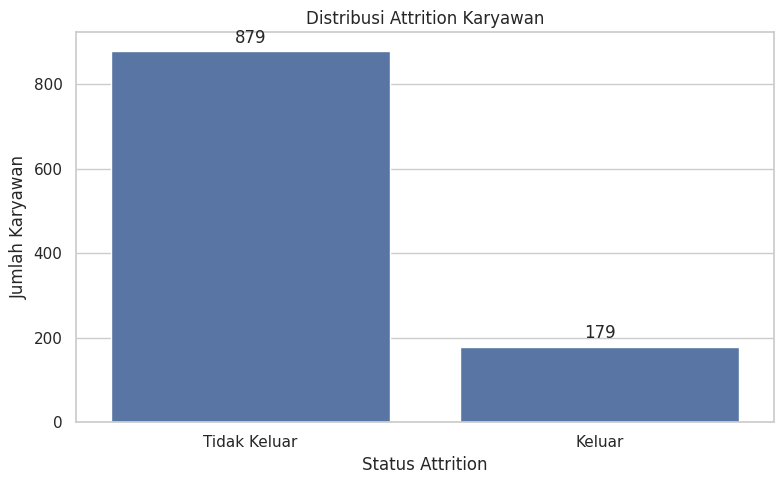

In [ ]:
# Menghitung jumlah karyawan berdasarkan label yang valid
attrition_plot = (
    df_labeled["Attrition"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

# Membuat grafik
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    x=["Tidak Keluar", "Keluar"],
    y=attrition_plot.values
)

plt.title("Distribusi Attrition Karyawan")
plt.xlabel("Status Attrition")
plt.ylabel("Jumlah Karyawan")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()


## Data Preparation / Preprocessing

In [ ]:
# Membuat salinan data agar dataset asli tetap terjaga
df_clean = df.copy()

# Memeriksa duplikasi EmployeeId
print("Jumlah EmployeeId duplikat:",
      df_clean["EmployeeId"].duplicated().sum())

# Memeriksa duplikasi seluruh baris
print("Jumlah baris duplikat:",
      df_clean.duplicated().sum())

# Memeriksa nilai unik pada kolom dengan kategori
categorical_columns = df_clean.select_dtypes(
    include=["object", "category"]
).columns.tolist()

for col in categorical_columns:
    print(f"\nKolom: {col}")
    print(df_clean[col].value_counts(dropna=False))

# Memeriksa nilai unik kolom Attrition
print("\nNilai unik Attrition:")
print(df_clean["Attrition"].value_counts(dropna=False))


Jumlah EmployeeId duplikat: 0
Jumlah baris duplikat: 0

Kolom: BusinessTravel
BusinessTravel
Travel_Rarely        1043
Travel_Frequently     277
Non-Travel            150
Name: count, dtype: int64

Kolom: Department
Department
Research & Development    961
Sales                     446
Human Resources            63
Name: count, dtype: int64

Kolom: EducationField
EducationField
Life Sciences       606
Medical             464
Marketing           159
Technical Degree    132
Other                82
Human Resources      27
Name: count, dtype: int64

Kolom: Gender
Gender
Male      882
Female    588
Name: count, dtype: int64

Kolom: JobRole
JobRole
Sales Executive              326
Research Scientist           292
Laboratory Technician        259
Manufacturing Director       145
Healthcare Representative    131
Manager                      102
Sales Representative          83
Research Director             80
Human Resources               52
Name: count, dtype: int64

Kolom: MaritalStatus
Mari

In [ ]:
#Menentukan kolom untuk analisis HR

# Memeriksa jumlah nilai unik pada setiap kolom
unique_summary = pd.DataFrame({
    "Jumlah Nilai Unik": df_clean.nunique(dropna=False),
    "Jumlah Missing": df_clean.isna().sum()
}).sort_values("Jumlah Nilai Unik")

display(unique_summary)

# Memeriksa kolom konstan
constant_columns = [
    col for col in df_clean.columns
    if df_clean[col].nunique(dropna=False) <= 1
]

print("Kolom konstan:", constant_columns)


,Jumlah Nilai Unik,Jumlah Missing
EmployeeCount,1,0
Over18,1,0
StandardHours,1,0
Gender,2,0
OverTime,2,0
PerformanceRating,2,0
BusinessTravel,3,0
Attrition,3,412
Department,3,0
MaritalStatus,3,0


Kolom konstan: ['EmployeeCount', 'Over18', 'StandardHours']


In [ ]:
#Membuat dataset khusus untuk analisis attrition

# Mengambil baris dengan label Attrition yang valid
df_eda = df_clean.dropna(subset=["Attrition"]).copy()

# Memastikan label berupa bilangan bulat
df_eda["Attrition"] = df_eda["Attrition"].astype(int)

# Memastikan label hanya 0 dan 1
df_eda = df_eda[
    df_eda["Attrition"].isin([0, 1])
].copy()

print("Ukuran data untuk analisis:", df_eda.shape)
print("\nDistribusi Attrition:")
display(df_eda["Attrition"].value_counts().sort_index())

# KPI dasar
total_labeled = len(df_eda)
total_left = int(df_eda["Attrition"].sum())
total_retained = total_labeled - total_left
rate = total_left / total_labeled * 100 if total_labeled else 0

print(f"Total karyawan berlabel: {total_labeled}")
print(f"Karyawan keluar: {total_left}")
print(f"Karyawan tidak keluar: {total_retained}")
print(f"Attrition rate berlabel: {rate:.2f}%")


Ukuran data untuk analisis: (1058, 35)

Distribusi Attrition:


,count
Attrition,
0,879
1,179


Total karyawan berlabel: 1058
Karyawan keluar: 179
Karyawan tidak keluar: 879
Attrition rate berlabel: 16.92%


In [ ]:
#Fungsi untuk menganalisis attrition rate
# Buat satu fungsi agar kita dapat membandingkan attrition rate berdasarkan departemen, jabatan, lembur, dan faktor lainnya secara konsisten.

def attrition_summary(data, column):
    summary = (
        data.groupby(column, dropna=False)
        .agg(
            Total_Karyawan=("Attrition", "size"),
            Karyawan_Keluar=("Attrition", "sum")
        )
        .reset_index()
    )

    summary["Attrition_Rate_Persen"] = (
        summary["Karyawan_Keluar"]
        / summary["Total_Karyawan"]
        * 100
    ).round(2)

    return summary.sort_values(
        "Attrition_Rate_Persen",
        ascending=False
    )

# Contoh analisis berdasarkan departemen
display(attrition_summary(df_eda, "Department"))


,Department,Total_Karyawan,Karyawan_Keluar,Attrition_Rate_Persen
2,Sales,319,66,20.69
0,Human Resources,38,6,15.79
1,Research & Development,701,107,15.26


**Exploratory Data Analysis (EDA)**

,OverTime,Total_Karyawan,Karyawan_Keluar,Attrition_Rate_Persen
1,Yes,307,98,31.92
0,No,751,81,10.79


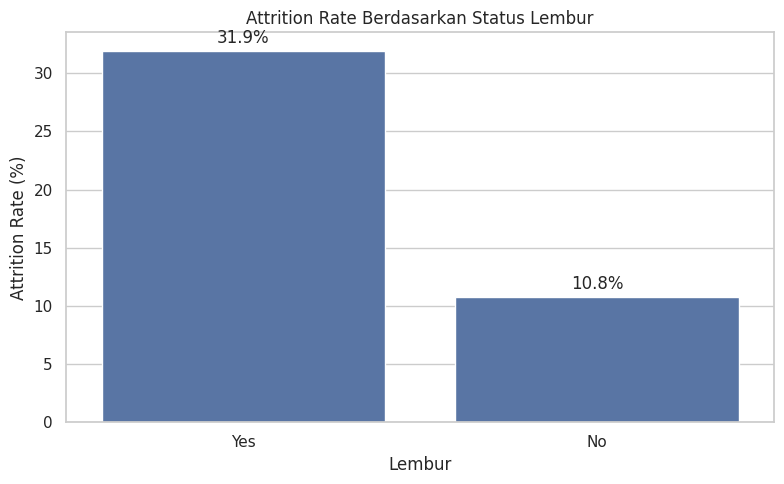

In [ ]:
#Attrition berdasarkan lembur (OverTime)


# Ringkasan attrition berdasarkan lembur
overtime_summary = attrition_summary(df_eda, "OverTime")
display(overtime_summary)

# Visualisasi attrition rate
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=overtime_summary,
    x="OverTime",
    y="Attrition_Rate_Persen"
)

plt.title("Attrition Rate Berdasarkan Status Lembur")
plt.xlabel("Lembur")
plt.ylabel("Attrition Rate (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()


,Department,Total_Karyawan,Karyawan_Keluar,Attrition_Rate_Persen
2,Sales,319,66,20.69
0,Human Resources,38,6,15.79
1,Research & Development,701,107,15.26


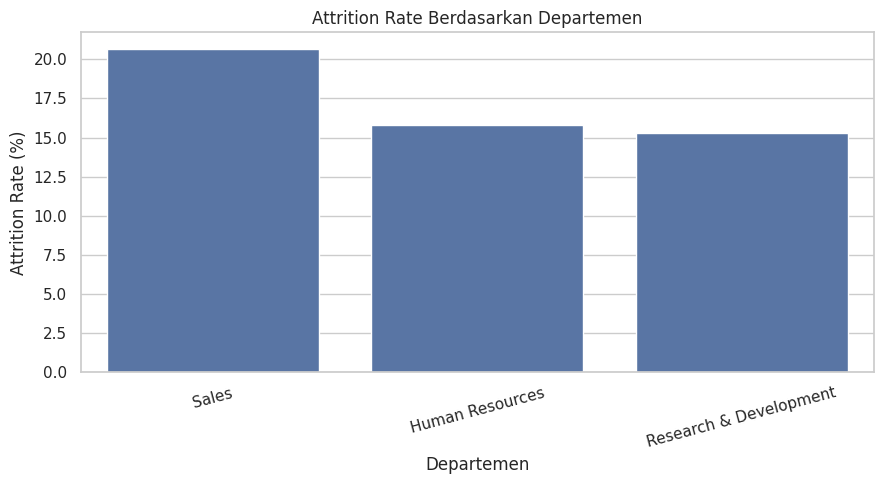

,JobRole,Total_Karyawan,Karyawan_Keluar,Attrition_Rate_Persen
8,Sales Representative,58,25,43.10
2,Laboratory Technician,188,49,26.06
1,Human Resources,30,6,20.00
6,Research Scientist,214,38,17.76
7,Sales Executive,232,39,16.81
0,Healthcare Representative,88,8,9.09
4,Manufacturing Director,107,7,6.54
3,Manager,79,5,6.33
5,Research Director,62,2,3.23


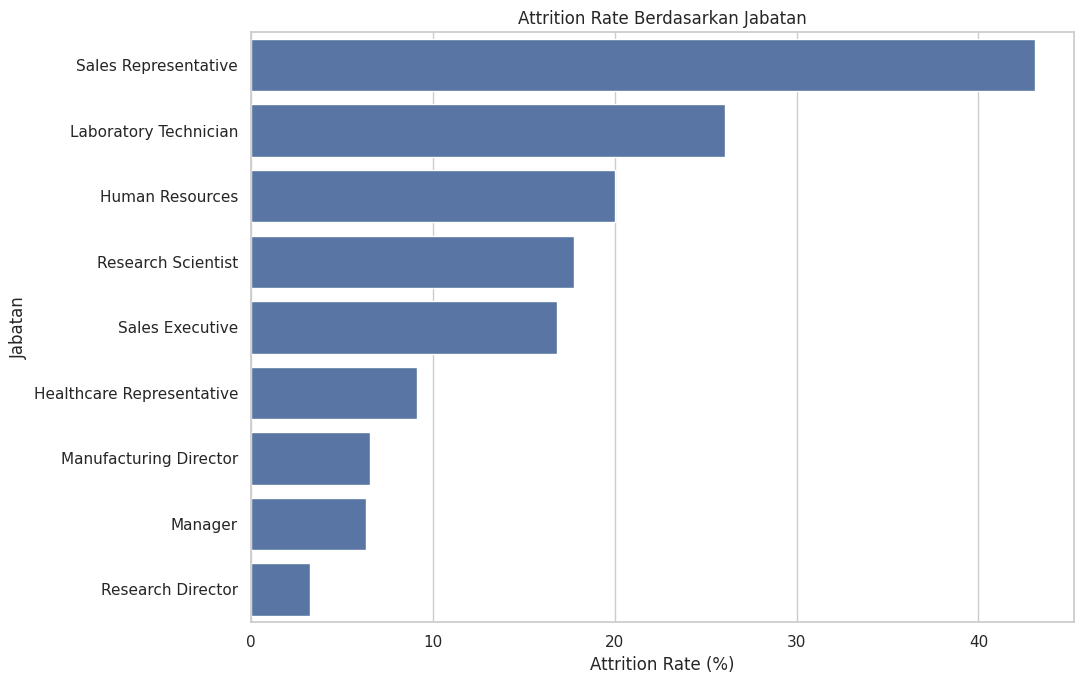

In [ ]:
# Attrition berdasarkan departemen dan jabatan


# Attrition berdasarkan departemen
department_summary = attrition_summary(df_eda, "Department")
display(department_summary)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=department_summary,
    x="Department",
    y="Attrition_Rate_Persen"
)
plt.title("Attrition Rate Berdasarkan Departemen")
plt.xlabel("Departemen")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Attrition berdasarkan jabatan
jobrole_summary = attrition_summary(df_eda, "JobRole")
display(jobrole_summary)

plt.figure(figsize=(11, 7))
sns.barplot(
    data=jobrole_summary,
    y="JobRole",
    x="Attrition_Rate_Persen"
)
plt.title("Attrition Rate Berdasarkan Jabatan")
plt.xlabel("Attrition Rate (%)")
plt.ylabel("Jabatan")
plt.tight_layout()
plt.show()


,JobSatisfaction,Total_Karyawan,Karyawan_Keluar,Attrition_Rate_Persen
0,1,205,46,22.44
2,3,318,62,19.50
1,2,195,32,16.41
3,4,340,39,11.47


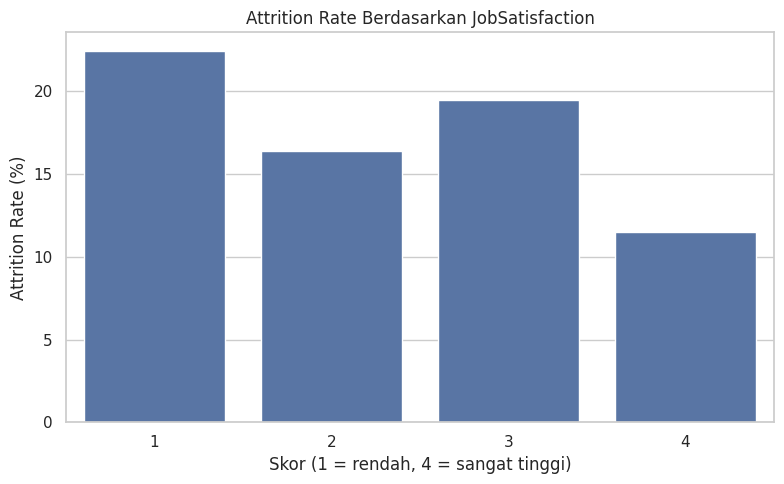

In [ ]:
# Attrition berdasarkan kepuasan kerja


satisfaction_columns = [
    "JobSatisfaction"

]

for col in satisfaction_columns:
    summary = attrition_summary(df_eda, col)
    display(summary)

    plt.figure(figsize=(8, 5))
    sns.barplot(
        data=summary,
        x=col,
        y="Attrition_Rate_Persen"
    )

    plt.title(f"Attrition Rate Berdasarkan {col}")
    plt.xlabel("Skor (1 = rendah, 4 = sangat tinggi)")
    plt.ylabel("Attrition Rate (%)")
    plt.tight_layout()
    plt.show()

,EnvironmentSatisfaction,Total_Karyawan,Karyawan_Keluar,Attrition_Rate_Persen
0,1,209,57,27.27
1,2,200,35,17.50
2,3,335,47,14.03
3,4,314,40,12.74


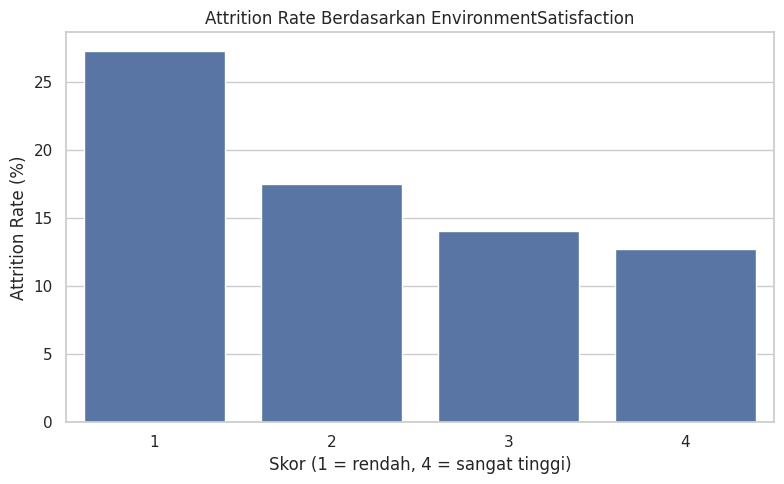

In [ ]:
# Attrition berdasarkan kepuasan kerja


satisfaction_columns = [
    "EnvironmentSatisfaction"
]

for col in satisfaction_columns:
    summary = attrition_summary(df_eda, col)
    display(summary)

    plt.figure(figsize=(8, 5))
    sns.barplot(
        data=summary,
        x=col,
        y="Attrition_Rate_Persen"
    )

    plt.title(f"Attrition Rate Berdasarkan {col}")
    plt.xlabel("Skor (1 = rendah, 4 = sangat tinggi)")
    plt.ylabel("Attrition Rate (%)")
    plt.tight_layout()
    plt.show()

,RelationshipSatisfaction,Total_Karyawan,Karyawan_Keluar,Attrition_Rate_Persen
0,1,201,46,22.89
3,4,323,52,16.10
1,2,210,32,15.24
2,3,324,49,15.12


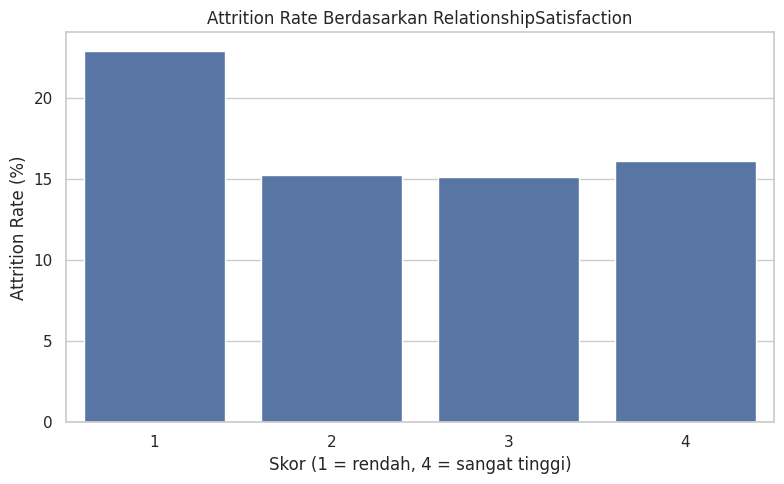

In [ ]:
# Attrition berdasarkan kepuasan kerja


satisfaction_columns = [
    "RelationshipSatisfaction"
]

for col in satisfaction_columns:
    summary = attrition_summary(df_eda, col)
    display(summary)

    plt.figure(figsize=(8, 5))
    sns.barplot(
        data=summary,
        x=col,
        y="Attrition_Rate_Persen"
    )

    plt.title(f"Attrition Rate Berdasarkan {col}")
    plt.xlabel("Skor (1 = rendah, 4 = sangat tinggi)")
    plt.ylabel("Attrition Rate (%)")
    plt.tight_layout()
    plt.show()

,WorkLifeBalance,Total_Karyawan,Karyawan_Keluar,Attrition_Rate_Persen
0,1,56,18,32.14
3,4,113,22,19.47
1,2,251,45,17.93
2,3,638,94,14.73


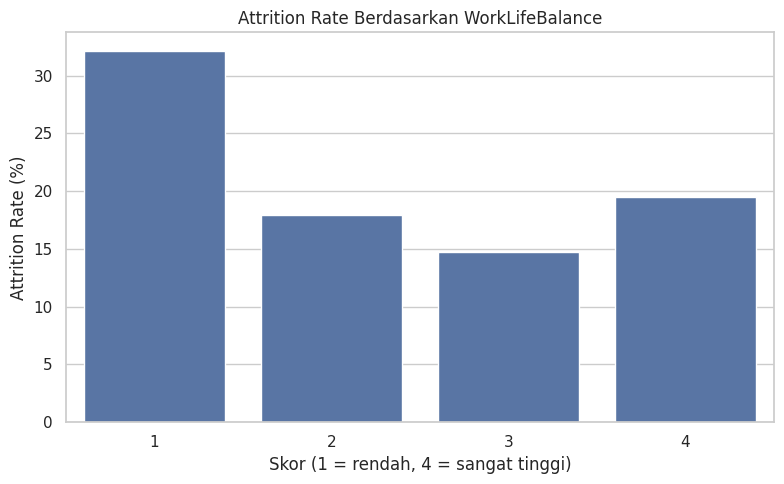

In [ ]:
# Attrition berdasarkan kepuasan kerja


satisfaction_columns = [
    "WorkLifeBalance"
]

for col in satisfaction_columns:
    summary = attrition_summary(df_eda, col)
    display(summary)

    plt.figure(figsize=(8, 5))
    sns.barplot(
        data=summary,
        x=col,
        y="Attrition_Rate_Persen"
    )

    plt.title(f"Attrition Rate Berdasarkan {col}")
    plt.xlabel("Skor (1 = rendah, 4 = sangat tinggi)")
    plt.ylabel("Attrition Rate (%)")
    plt.tight_layout()
    plt.show()

/tmp/ipykernel_836/2414257781.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data.groupby(column, dropna=False)


,AgeGroup,Total_Karyawan,Karyawan_Keluar,Attrition_Rate_Persen
0,18-25,92,35,38.04
1,26-35,431,84,19.49
4,56+,39,6,15.38
2,36-45,328,36,10.98
3,46-55,168,18,10.71


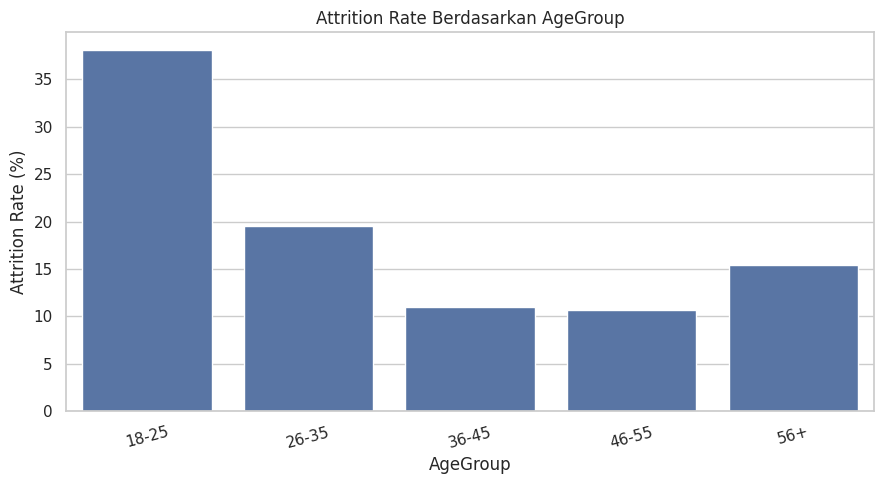

In [ ]:
# Attrition berdasarkan usia, pendapatan, dan masa kerja


# Membuat kelompok usia
df_eda["AgeGroup"] = pd.cut(
    df_eda["Age"],
    bins=[17, 25, 35, 45, 55, 100],
    labels=["18-25", "26-35", "36-45", "46-55", "56+"]
)

group_columns = ["AgeGroup"]

for col in group_columns:
    summary = attrition_summary(df_eda, col)
    display(summary)

    plt.figure(figsize=(9, 5))
    sns.barplot(
        data=summary,
        x=col,
        y="Attrition_Rate_Persen"
    )

    plt.title(f"Attrition Rate Berdasarkan {col}")
    plt.xlabel(col)
    plt.ylabel("Attrition Rate (%)")
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()


/tmp/ipykernel_836/2414257781.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data.groupby(column, dropna=False)


,IncomeGroup,Total_Karyawan,Karyawan_Keluar,Attrition_Rate_Persen
0,<= 3000,286,82,28.67
1,3001-5000,256,42,16.41
2,5001-10000,297,35,11.78
3,> 10000,219,20,9.13


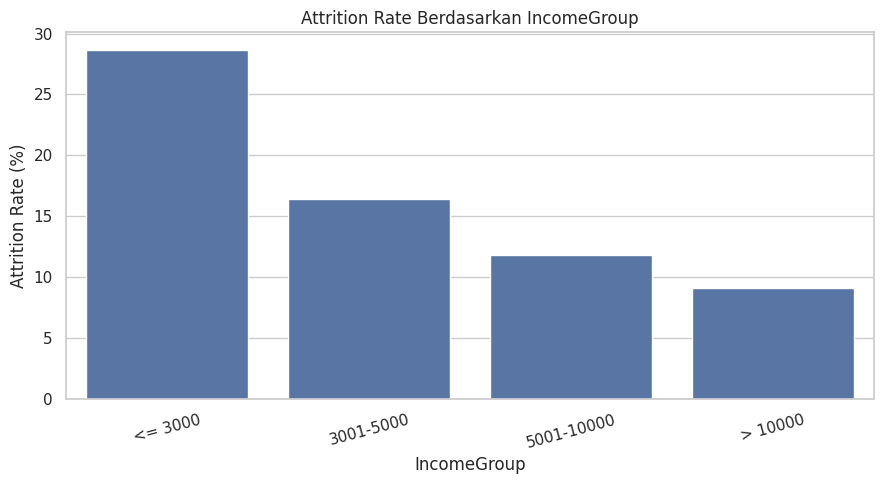

In [ ]:
# Attrition berdasarkan usia, pendapatan, dan masa kerja

# Membuat kelompok pendapatan bulanan
df_eda["IncomeGroup"] = pd.cut(
    df_eda["MonthlyIncome"],
    bins=[-1, 3000, 5000, 10000, np.inf],
    labels=["<= 3000", "3001-5000", "5001-10000", "> 10000"]
)


group_columns = ["IncomeGroup"]

for col in group_columns:
    summary = attrition_summary(df_eda, col)
    display(summary)

    plt.figure(figsize=(9, 5))
    sns.barplot(
        data=summary,
        x=col,
        y="Attrition_Rate_Persen"
    )

    plt.title(f"Attrition Rate Berdasarkan {col}")
    plt.xlabel(col)
    plt.ylabel("Attrition Rate (%)")
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()


/tmp/ipykernel_836/2414257781.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data.groupby(column, dropna=False)


,TenureGroup,Total_Karyawan,Karyawan_Keluar,Attrition_Rate_Persen
0,0-1 tahun,159,55,34.59
1,2-3 tahun,186,37,19.89
2,4-5 tahun,208,29,13.94
3,6-10 tahun,325,43,13.23
4,> 10 tahun,180,15,8.33


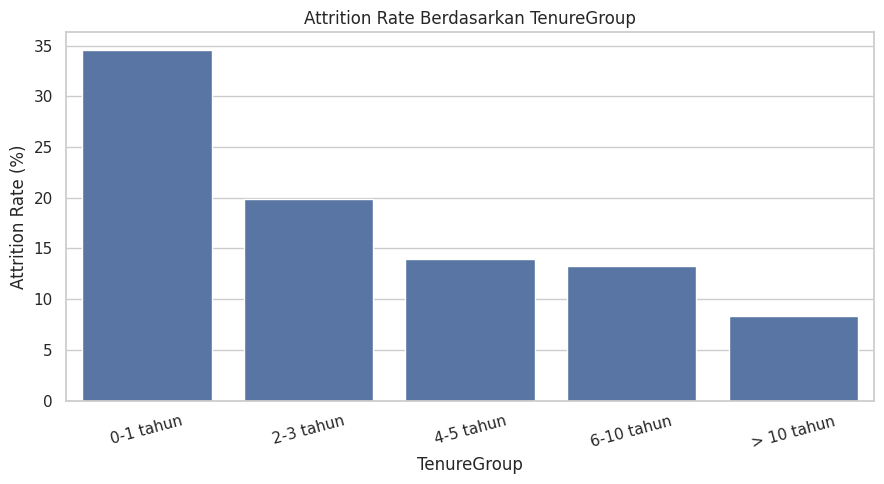

In [ ]:
# Attrition berdasarkan usia, pendapatan, dan masa kerja

# Membuat kelompok masa kerja
df_eda["TenureGroup"] = pd.cut(
    df_eda["YearsAtCompany"],
    bins=[-1, 1, 3, 5, 10, np.inf],
    labels=["0-1 tahun", "2-3 tahun", "4-5 tahun",
            "6-10 tahun", "> 10 tahun"]
)

group_columns = ["TenureGroup"]

for col in group_columns:
    summary = attrition_summary(df_eda, col)
    display(summary)

    plt.figure(figsize=(9, 5))
    sns.barplot(
        data=summary,
        x=col,
        y="Attrition_Rate_Persen"
    )

    plt.title(f"Attrition Rate Berdasarkan {col}")
    plt.xlabel(col)
    plt.ylabel("Attrition Rate (%)")
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()


In [ ]:
# Menyusun tabel faktor attrition untuk dashboard


# Faktor kategorikal utama untuk dashboard
dashboard_factors = [
    "OverTime",
    "Department",
    "JobRole",
    "BusinessTravel",
    "MaritalStatus",
    "JobSatisfaction",
    "EnvironmentSatisfaction",
    "WorkLifeBalance",
    "AgeGroup",
    "IncomeGroup",
    "TenureGroup"
]

dashboard_summaries = {}

for factor in dashboard_factors:
    summary = attrition_summary(df_eda, factor)
    dashboard_summaries[factor] = summary
    print(f"\nRingkasan: {factor}")
    display(summary)

# Menggabungkan ringkasan menjadi satu tabel
dashboard_data = pd.concat(
    [
        summary.assign(Faktor=factor)
        for factor, summary in dashboard_summaries.items()
    ],
    ignore_index=True
)

# Menyimpan hasil analisis
dashboard_data.to_csv(
    "attrition_dashboard_summary.csv",
    index=False
)

print("File attrition_dashboard_summary.csv berhasil dibuat.")



Ringkasan: OverTime


,OverTime,Total_Karyawan,Karyawan_Keluar,Attrition_Rate_Persen
1,Yes,307,98,31.92
0,No,751,81,10.79



Ringkasan: Department


,Department,Total_Karyawan,Karyawan_Keluar,Attrition_Rate_Persen
2,Sales,319,66,20.69
0,Human Resources,38,6,15.79
1,Research & Development,701,107,15.26



Ringkasan: JobRole


...

,IncomeGroup,Total_Karyawan,Karyawan_Keluar,Attrition_Rate_Persen
0,<= 3000,286,82,28.67
1,3001-5000,256,42,16.41
2,5001-10000,297,35,11.78
3,> 10000,219,20,9.13



Ringkasan: TenureGroup


/tmp/ipykernel_836/2414257781.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data.groupby(column, dropna=False)


,TenureGroup,Total_Karyawan,Karyawan_Keluar,Attrition_Rate_Persen
0,0-1 tahun,159,55,34.59
1,2-3 tahun,186,37,19.89
2,4-5 tahun,208,29,13.94
3,6-10 tahun,325,43,13.23
4,> 10 tahun,180,15,8.33


File attrition_dashboard_summary.csv berhasil dibuat.


In [ ]:
# Menyusun catatan hasil analisis


for factor in ["OverTime", "Department", "JobRole",
               "JobSatisfaction", "AgeGroup",
               "IncomeGroup", "TenureGroup"]:

    summary = attrition_summary(df_eda, factor)

    print(f"\nFaktor: {factor}")
    display(summary.head(3))



Faktor: OverTime


,OverTime,Total_Karyawan,Karyawan_Keluar,Attrition_Rate_Persen
1,Yes,307,98,31.92
0,No,751,81,10.79



Faktor: Department


,Department,Total_Karyawan,Karyawan_Keluar,Attrition_Rate_Persen
2,Sales,319,66,20.69
0,Human Resources,38,6,15.79
1,Research & Development,701,107,15.26



Faktor: JobRole


...

/tmp/ipykernel_836/2414257781.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data.groupby(column, dropna=False)


,IncomeGroup,Total_Karyawan,Karyawan_Keluar,Attrition_Rate_Persen
0,<= 3000,286,82,28.67
1,3001-5000,256,42,16.41
2,5001-10000,297,35,11.78



Faktor: TenureGroup


/tmp/ipykernel_836/2414257781.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data.groupby(column, dropna=False)


,TenureGroup,Total_Karyawan,Karyawan_Keluar,Attrition_Rate_Persen
0,0-1 tahun,159,55,34.59
1,2-3 tahun,186,37,19.89
2,4-5 tahun,208,29,13.94


## Modeling

In [ ]:
# Menyiapkan dataset untuk modeling


# Import library untuk machine learning
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Mengambil hanya baris dengan label Attrition valid
df_model = df.dropna(subset=["Attrition"]).copy()

# Memastikan target hanya terdiri dari kelas 0 dan 1
df_model = df_model[df_model["Attrition"].isin([0, 1])].copy()
df_model["Attrition"] = df_model["Attrition"].astype(int)

print("Ukuran dataset modeling:", df_model.shape)
print("\nDistribusi target:")
display(df_model["Attrition"].value_counts())


Ukuran dataset modeling: (1058, 35)

Distribusi target:


,count
Attrition,
0,879
1,179


In [ ]:
# Menentukan fitur dan target

# Mengidentifikasi kolom konstan
constant_cols = [
    col for col in df_model.columns
    if df_model[col].nunique(dropna=False) <= 1
]

# Kolom yang tidak digunakan sebagai fitur
drop_cols = ["Attrition", "EmployeeId"] + constant_cols
drop_cols = list(set(drop_cols))

# Menyiapkan fitur dan target
X = df_model.drop(columns=drop_cols, errors="ignore")
y = df_model["Attrition"]

print("Jumlah fitur:", X.shape[1])
print("Jumlah data:", X.shape[0])
print("\nDistribusi target:")
print(y.value_counts(normalize=True).mul(100).round(2))
print("\nKolom fitur:")
print(X.columns.tolist())


Jumlah fitur: 30
Jumlah data: 1058

Distribusi target:
Attrition
0    83.08
1    16.92
Name: proportion, dtype: float64

Kolom fitur:
['Age', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


In [ ]:
# Membagi data latih dan data uji

# Membagi data menjadi train dan test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data train:", X_train.shape[0])
print("Jumlah data test:", X_test.shape[0])

print("\nDistribusi kelas pada data train:")
display(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nDistribusi kelas pada data test:")
display(y_test.value_counts(normalize=True).mul(100).round(2))


Jumlah data train: 846
Jumlah data test: 212

Distribusi kelas pada data train:


,proportion
Attrition,
0,83.1
1,16.9



Distribusi kelas pada data test:


,proportion
Attrition,
0,83.02
1,16.98


In [ ]:
# Membuat preprocessing pipeline

# Memisahkan fitur numerik dan kategorikal
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Fitur numerik:", numeric_features)
print("Fitur kategorikal:", categorical_features)

# Pipeline fitur numerik
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Pipeline fitur kategorikal
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Menggabungkan preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline berhasil dibuat.")


Fitur numerik: ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']
Fitur kategorikal: ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']
Preprocessing pipeline berhasil dibuat.


In [ ]:
# Melatih model baseline dan model utama

# Menentukan model yang akan dibandingkan
models = {
    "Dummy Baseline": DummyClassifier(strategy="most_frequent"),

    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
}

# Melatih dan mengevaluasi model
trained_models = {}
results = []

for model_name, classifier in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    # Melatih model menggunakan data train
    pipeline.fit(X_train, y_train)

    # Prediksi pada data test
    y_pred = pipeline.predict(X_test)

    # Menghitung metrik evaluasi
    result = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        )
    }

    if hasattr(pipeline, "predict_proba"):
        y_prob = pipeline.predict_proba(X_test)[:, 1]
        result["ROC-AUC"] = roc_auc_score(y_test, y_prob)
    else:
        result["ROC-AUC"] = np.nan

    results.append(result)
    trained_models[model_name] = pipeline

# Menampilkan perbandingan model
results_df = pd.DataFrame(results).sort_values(
    "F1-Score", ascending=False
)

display(results_df.round(4))


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
1,Logistic Regression,0.7311,0.3600,0.7500,0.4865,0.8078
2,Random Forest,0.8538,0.7778,0.1944,0.3111,0.8108
0,Dummy Baseline,0.8302,0.0000,0.0000,0.0000,0.5000


## Evaluation

Model kandidat terbaik: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

Tidak Keluar       0.93      0.73      0.82       176
      Keluar       0.36      0.75      0.49        36

    accuracy                           0.73       212
   macro avg       0.65      0.74      0.65       212
weighted avg       0.84      0.73      0.76       212



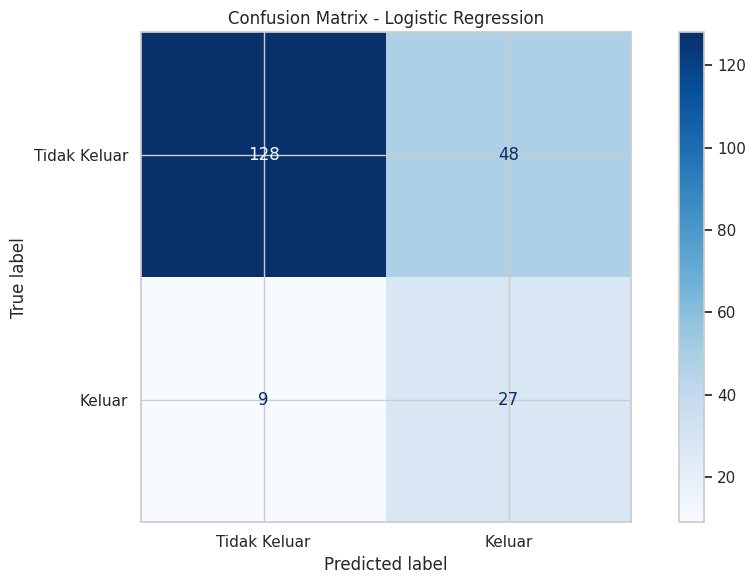

In [ ]:
# Mengevaluasi model terbaik


# Memilih kandidat dengan F1-score tertinggi
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Model kandidat terbaik:", best_model_name)

# Prediksi menggunakan model terpilih
y_pred_best = best_model.predict(X_test)

# Classification report
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_best,
        target_names=["Tidak Keluar", "Keluar"],
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred_best,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Tidak Keluar", "Keluar"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()


In [ ]:
# Menyimpan model


import joblib
import os

# Membuat folder model
os.makedirs("model", exist_ok=True)

# Menyimpan model beserta nama fitur
model_artifact = {
    "model": best_model,
    "features": X.columns.tolist(),
    "model_name": best_model_name
}

model_path = "model/attrition_model.joblib"

joblib.dump(model_artifact, model_path)

print("Model berhasil disimpan:", model_path)
print("Ukuran file:", round(os.path.getsize(model_path) / 1024, 2), "KB")


Model berhasil disimpan: model/attrition_model.joblib
Ukuran file: 8.29 KB


In [ ]:
# Menyimpan hasil evaluasi

# Menyimpan hasil perbandingan model
results_df.to_csv(
    "model/model_evaluation_results.csv",
    index=False
)

print("Hasil evaluasi berhasil disimpan.")


Hasil evaluasi berhasil disimpan.
